# Módulo 3 — Extracción de Características, Textura y Dinámica Temporal
**PupilTrack — PSIB, ITBA (2do Q 2026)**

3.1: descriptores morfométricos y de textura en un frame segmentado.
3.2: procesamiento del video completo -> curva temporal del diámetro pupilar
y parámetros fisiológicos (esto corre vía `run_pipeline.py`, acá se explora
y se valida sobre un frame/video de prueba).

In [1]:
VIDEO_PATH = ""
ROI_MANUAL = None
FRAME_INDICE = None
NIVELES_GLCM = 32

## Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pupiltrack import acquisition as acq
from pupiltrack import segmentation as seg
from pupiltrack import morphology as morf
from pupiltrack import texture as tex
from pupiltrack import temporal as tmp

plt.rcParams["figure.figsize"] = (6, 4)

def mostrar(img, titulo="", cmap="gray"):
    plt.figure(); plt.imshow(img, cmap=cmap); plt.title(titulo); plt.axis("off"); plt.show()

## Carga del frame de trabajo

Usando imagen sintética de prueba.


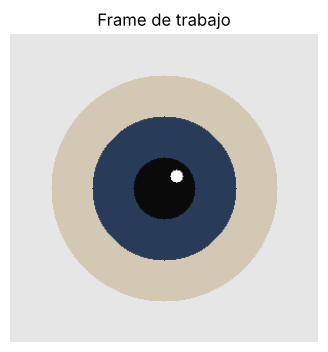

In [3]:
def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img

if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    frames, fps = acq.extraer_frames(VIDEO_PATH)
    frame_completo = acq.frame_representativo(frames, FRAME_INDICE)
    if ROI_MANUAL is not None:
        x, y, w, h = ROI_MANUAL
        frame = frame_completo[y:y+h, x:x+w]
    else:
        frame, roi = acq.seleccionar_roi(frame_completo)
else:
    frame = generar_ojo_sintetico()
    print("Usando imagen sintética de prueba.")

gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
mostrar(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), "Frame de trabajo")

## 3.1 — Descriptores morfométricos (forma)

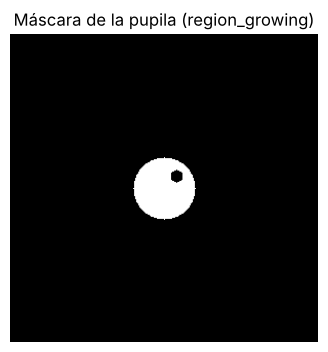

Área (px): 2714.0
Perímetro (px): 240.45079348883237
Centroide (x,y): 149.52689756816508 150.47310243183492
Circularidad: 0.5899
Excentricidad: 0.2251


In [4]:
mascara = tmp.segmentar_frame(gris, metodo="region_growing")
mostrar(mascara, "Máscara de la pupila (region_growing)")

desc = morf.descriptores_morfometricos(mascara)
print("Área (px):", desc["area_px"])
print("Perímetro (px):", desc["perimetro_px"])
print("Centroide (x,y):", desc["centroide_x"], desc["centroide_y"])
print("Circularidad:", desc["circularidad"])
print("Excentricidad:", desc["excentricidad"])

## 3.1 — Textura de primer orden (media, desvío, entropía, asimetría) por canal RGB

In [5]:
primer_orden = tex.textura_primer_orden_rgb(frame)
for canal, valores in primer_orden.items():
    print(canal, valores)

R {'media': 191.889, 'desvio': 71.693, 'entropia': 1.518, 'asimetria': -1.726}
G {'media': 192.167, 'desvio': 65.44, 'entropia': 1.518, 'asimetria': -1.685}
B {'media': 191.327, 'desvio': 57.645, 'entropia': 1.518, 'asimetria': -1.52}


## 3.1 — Textura de segundo orden (GLCM)

Matriz de co-ocurrencia construida en las 4 direcciones (0°, 45°, 90°, 135°),
normalizada como distribución de probabilidad, promediada sobre las 4
direcciones para que sea invariante a la orientación del estroma iridiano.

In [6]:
glcm_rgb = tex.textura_glcm_rgb(frame, niveles=NIVELES_GLCM)
for canal, atributos in glcm_rgb.items():
    print(canal, atributos)

canal_top = tex.canal_mas_textural(glcm_rgb, atributo="contrast")
print(f"\nCanal con mayor riqueza textural (por contraste GLCM): {canal_top}")

R {'contrast': 2.0164, 'homogeneity': 0.9896, 'energy': 0.6398, 'correlation': 0.9868}
G {'contrast': 1.637, 'homogeneity': 0.989, 'energy': 0.6398, 'correlation': 0.9876}
B {'contrast': 1.1354, 'homogeneity': 0.9885, 'energy': 0.6398, 'correlation': 0.9885}

Canal con mayor riqueza textural (por contraste GLCM): R


**Pregunta de la guía:** ¿qué canal aporta mayor riqueza textural del estroma iridiano? Ver `canal_top` de arriba.

## 3.2 — Procesamiento en video y curva temporal

Esto es lo que corre `run_pipeline.py` para todo el video. Acá se valida
sobre `VIDEO_PATH` (o el sintético que genera `generar_video_sintetico.py`
si todavía no hay un registro real).

In [7]:
from pupiltrack.config import cargar_config

if os.path.exists("../config.yaml"):
    cfg = cargar_config("../config.yaml")
else:
    from pupiltrack.config import DEFAULTS
    cfg = DEFAULTS
    cfg["video"]["path"] = VIDEO_PATH or "../data/registro_ejemplo.mp4"

if os.path.exists(cfg["video"]["path"]):
    df, fps, roi = tmp.procesar_video(cfg)
    print(f"Frames: {len(df)} | fps: {fps:.1f} | ROI: {roi}")
    display(df.head())

    plt.figure()
    plt.plot(df["tiempo_s"], df["diametro_px"])
    plt.xlabel("Tiempo (s)"); plt.ylabel("Diámetro (px)")
    plt.title("Curva temporal del diámetro pupilar")
    plt.grid(alpha=0.3)
    plt.show()

    parametros = tmp.calcular_parametros_fisiologicos(df, fps, tipo=cfg["video"]["tipo"])
    print("\nParámetros fisiológicos:")
    for k, v in parametros.items():
        print(f"  {k}: {v}")
else:
    print(f"No se encontró el video en {cfg['video']['path']}. Correr generar_video_sintetico.py o ajustar VIDEO_PATH.")

No se encontró el video en data/registro_ejemplo.mp4. Correr generar_video_sintetico.py o ajustar VIDEO_PATH.


**Pregunta de la guía (3.2):** validar diámetro/área automático contra
medición manual en un subconjunto de frames anotados (MAE/RMSE). Pendiente:
requiere mediciones manuales sobre video real — completar con esos datos
cuando estén disponibles.